# Laboratory work 1 — Regression on the Insurance dataset

In [ ]:
# Dataset: https://www.kaggle.com/datasets/mirichoi0218/insurance

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

### Load dataset

In [2]:
# Relative path to the Kaggle CSV
path = "data/insurance.csv"

# Fail early with a clear message if the file is missing
try:
    df = pd.read_csv(path)
except Exception:
    raise FileNotFoundError(f"Could not find the dataset at {path}. Please ensure the file exists.")

# Quick structural check: size, first rows, dtypes
print("Dataset shape:", df.shape)
print(df.head())
print(df.info())

Dataset shape: (1338, 7)
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None


### Initial data analysis

In [3]:
# Summary statistics for numeric and categorical columns
print("\nDescriptive statistics:")
print(df.describe(include="all"))

# Check for missing values
print("\nMissing values:")
print(df.isna().sum())

# Count exact duplicate rows
print("\nDuplicated rows:", df.duplicated().sum())


Descriptive statistics:
                age   sex          bmi     children smoker     region  \
count   1338.000000  1338  1338.000000  1338.000000   1338       1338   
unique          NaN     2          NaN          NaN      2          4   
top             NaN  male          NaN          NaN     no  southeast   
freq            NaN   676          NaN          NaN   1064        364   
mean      39.207025   NaN    30.663397     1.094918    NaN        NaN   
std       14.049960   NaN     6.098187     1.205493    NaN        NaN   
min       18.000000   NaN    15.960000     0.000000    NaN        NaN   
25%       27.000000   NaN    26.296250     0.000000    NaN        NaN   
50%       39.000000   NaN    30.400000     1.000000    NaN        NaN   
75%       51.000000   NaN    34.693750     2.000000    NaN        NaN   
max       64.000000   NaN    53.130000     5.000000    NaN        NaN   

             charges  
count    1338.000000  
unique           NaN  
top              NaN  
freq  

In [4]:
# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

# Cardinality per column helps tell categorical from continuous features
print("\nUnique values:")
for col in df.columns:
    print(col, ":", df[col].nunique())

Shape after removing duplicates: (1337, 7)

Unique values:
age : 47
sex : 2
bmi : 548
children : 6
smoker : 2
region : 4
charges : 1337


### Detect anomalies

In [5]:
# Select numeric columns for outlier detection.
numeric_cols = ["age", "bmi", "children", "charges"]

print("\nPotential numeric outliers by IQR:")

# Store the number of detected outliers for each column.
outlier_summary = {}

# Check each numeric column using the IQR method.
for col in numeric_cols:
    # Calculate the first and third quartiles.
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    # Calculate the interquartile range.
    iqr = q3 - q1

    # Define the lower and upper outlier boundaries.
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    # Count values outside the defined boundaries.
    count = int(((df[col] < low) | (df[col] > high)).sum())

    # Save the outlier count for the column.
    outlier_summary[col] = count

    # Print the number of detected outliers.
    print(f"{col}: {count}")

# Keep potential outliers because they may represent valid observations.
# High insurance charges are not necessarily data-entry errors.


Potential numeric outliers by IQR:
age: 0
bmi: 9
children: 0
charges: 139


#### Parameter notes — outlier detection
- **Columns checked:** `age`, `bmi`, `children`, `charges` — the numeric columns (the categorical ones have no meaningful IQR).
- **Quartiles 0.25 / 0.75 and multiplier 1.5:** Tukey's standard fence. For roughly normal data it flags only about 0.7% of points, so it works as a sensitive screen, not a verdict.
- **Result:** age 0, children 0, bmi 9, charges 139 (about 10% of 1,337 rows). The large count for `charges` reflects its skewed distribution rather than data errors, which is why the rows are kept.

### Visual EDA

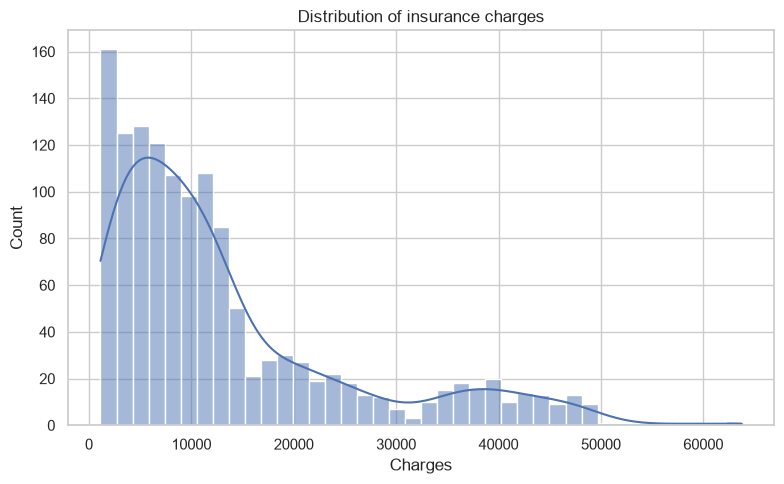

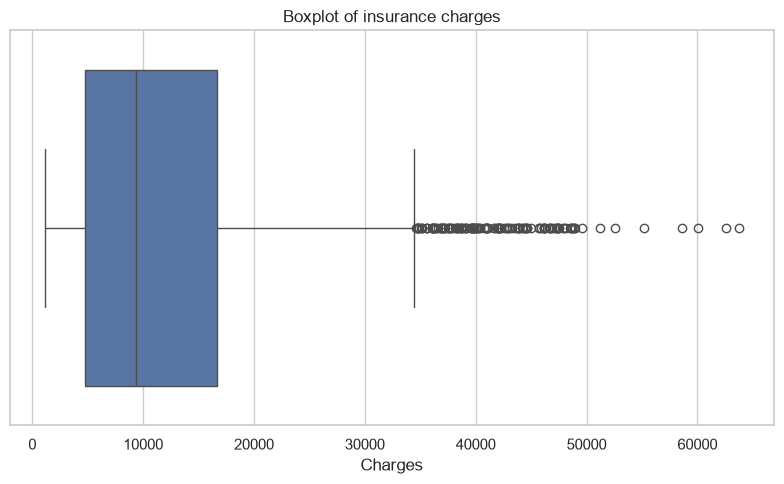

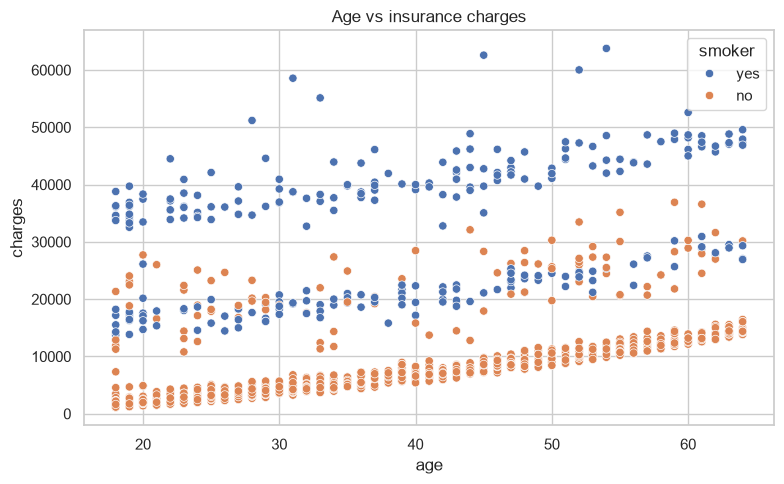

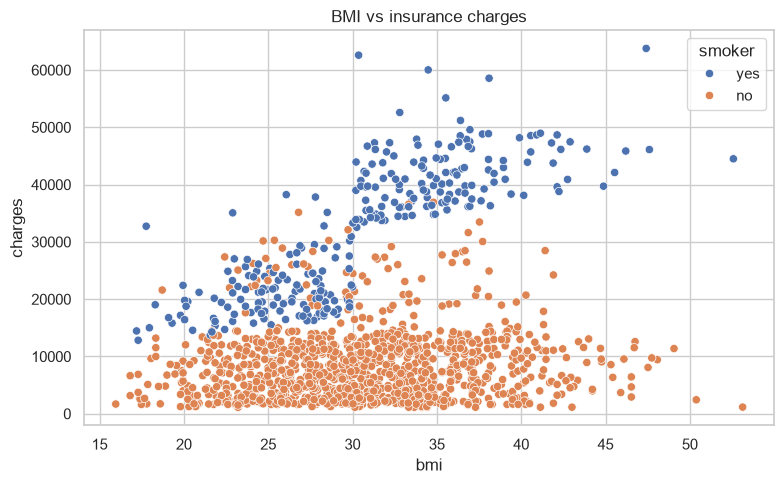

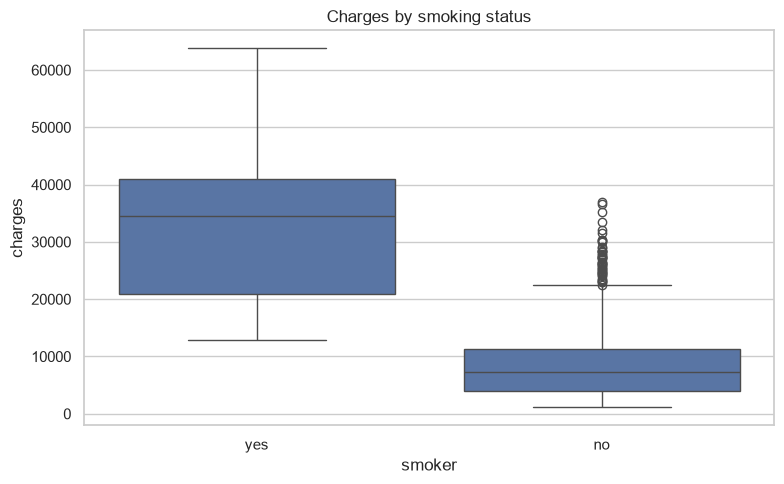

In [6]:
# Consistent plot style
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
# Target distribution (mean 13.3k > median 9.4k hints at right skew)
sns.histplot(df["charges"], bins=40, kde=True)
plt.title("Distribution of insurance charges")
plt.xlabel("Charges")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
# Boxplot of the target to show the upper tail
sns.boxplot(x=df["charges"])
plt.title("Boxplot of insurance charges")
plt.xlabel("Charges")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
# Age vs charges, coloured by smoker status
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Age vs insurance charges")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
# BMI vs charges, coloured by smoker status
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("BMI vs insurance charges")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
# Charges for smokers vs non-smokers
sns.boxplot(data=df, x="smoker", y="charges")
plt.title("Charges by smoking status")
plt.tight_layout()
plt.show()

#### Parameter notes — EDA plots
- **`bins=40` with `kde=True`:** with about 1,300 rows, 40 bins resolve the shape and long right tail of `charges` without many empty bins; the KDE curve smooths the outline.
- **`hue="smoker"`** on the age and BMI scatter plots: `smoker` is the strongest predictor (r ≈ 0.79 with `charges` in the correlation table below), so colouring by it reveals structure that would otherwise look like noise.
- **`figsize=(8, 5)` and `tight_layout()`:** layout only, no analytical effect.

### Correlation analysis

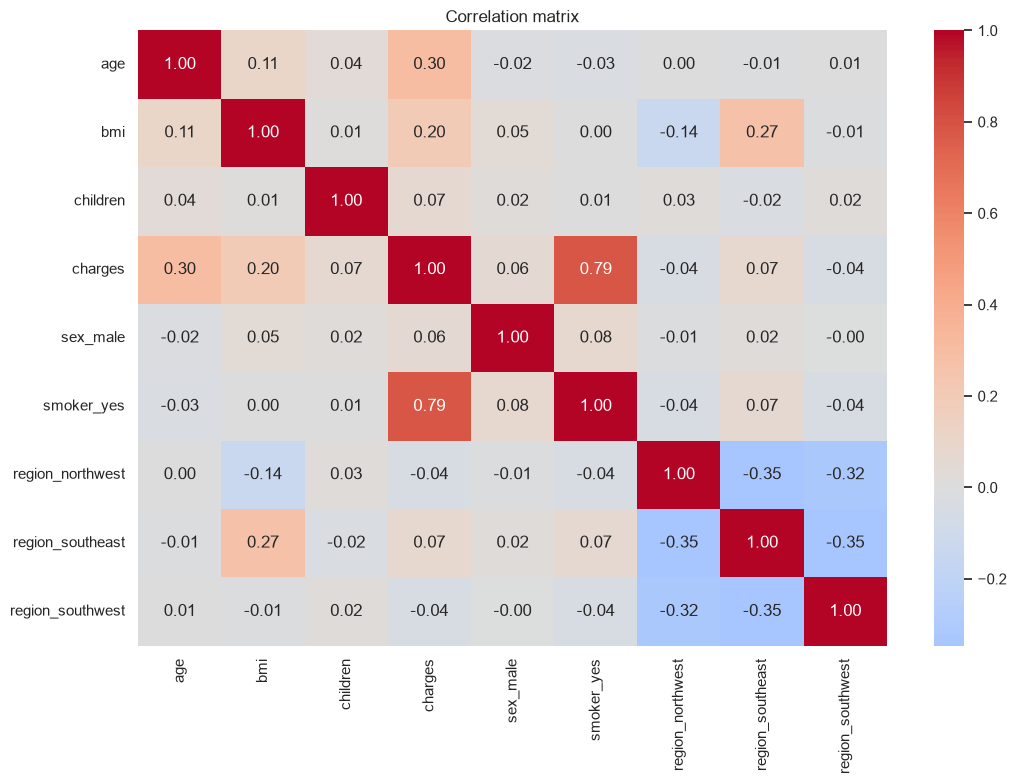


Correlations with target:
charges             1.000000
smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64


In [7]:
# Convert categorical columns into numerical values.
encoded_corr = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=int
)

# Calculate the correlation matrix.
corr = encoded_corr.corr(numeric_only=True)

# Create a figure for the correlation heatmap.
plt.figure(figsize=(11, 8))

# Display correlations as a heatmap.
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)

# Add a title to the heatmap.
plt.title("Correlation matrix")

# Adjust the layout.
plt.tight_layout()

# Show the plot.
plt.show()

print("\nCorrelations with target:")

# Show correlations with the target variable.
print(corr["charges"].sort_values(ascending=False))

### Data preparation

In [8]:
# Encode categorical variables into numerical columns.
data = pd.get_dummies(
    df,
    columns=["sex", "smoker", "region"],
    drop_first=True,
    dtype=float
)

# Define input features.
X = data.drop(columns="charges")

# Define the target variable.
y = data["charges"]

# Split the data into training and test sets.
# 70% is used for training and 30% for testing.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

# Print the sizes of the training and test sets.
print("\nTrain size:", len(X_train))
print("Test size:", len(X_test))

# Print the names of the input features.
print("Feature columns:", list(X.columns))


Train size: 935
Test size: 402
Feature columns: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


#### Parameter notes — encoding and split
- **`drop_first=True`:** drops one dummy per categorical column (`sex_female`, `smoker_no`, `region_northeast`). Keeping all dummies would make the columns sum to a constant and be perfectly collinear with the intercept, which destabilizes plain linear regression and the NumPy solution.
- **`dtype=float`:** gives a purely numeric matrix that scikit-learn, XGBoost and `to_numpy(dtype=float)` accept directly (the correlation step uses `int`, which is equivalent there).
- **`test_size=0.30`:** 935 training and 402 test rows. A 30% hold-out keeps the test estimate reasonably stable on a small dataset while leaving enough rows to train on.
- **`random_state=42`:** makes the split reproducible so every model is compared on the same rows.

### Evaluation helper

In [9]:
# Evaluate a model and calculate its performance metrics.
def evaluate_model(name, model, X_train, X_test, y_train, y_test):
    # Measure the model training time.
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start

    # Generate predictions for training and test data.
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    # Store the main evaluation metrics.
    result = {
        "Model": name,
        "Train R2": r2_score(y_train, train_pred),
        "Test R2": r2_score(y_test, test_pred),
        "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred)),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred)),
        "Test MAE": mean_absolute_error(y_test, test_pred),
        "Runtime (s)": fit_time,
    }

    # Return the metrics and test predictions.
    return result, test_pred

#### Parameter notes — evaluation metrics
- **R²:** share of variance explained; reported for train and test to expose overfitting.
- **RMSE:** in dollars and squares errors before averaging, so it punishes large misses. It matches the squared-error objective used in training and is the notebook's ranking metric.
- **MAE:** average absolute miss in dollars; less sensitive to the extreme charges, so it describes a "typical" error.
- **Runtime:** wall-clock `fit` time from `time.perf_counter()`; very small values (milliseconds) are noisy on a single run.

### Approach 1 — Scikit-learn

In [10]:
# Create empty containers for model results and predictions.
results = []
predictions = {}

# Initialize the Linear Regression model.
sk_model = LinearRegression()

# Train the model and evaluate its performance.
res, pred = evaluate_model(
    "Scikit-learn LinearRegression",
    sk_model, X_train, X_test, y_train, y_test
)

# Save the evaluation results.
results.append(res)

# Save the test predictions.
predictions["Scikit-learn LinearRegression"] = pred

print("\nScikit-learn coefficients:")

# Display the model coefficients for each feature.
print(pd.Series(sk_model.coef_, index=X.columns))

# Display the intercept of the model.
print("Intercept:", sk_model.intercept_)


Scikit-learn coefficients:
age                   251.246172
bmi                   328.383096
children              522.155362
sex_male             -111.907161
smoker_yes          22874.446407
region_northwest     -465.746596
region_southeast     -936.099326
region_southwest     -765.583886
dtype: float64
Intercept: -11516.781029185728


### Approach 2 — Vanilla NumPy

In [11]:
# Prepare the data for manual linear regression.
# Add a column of ones for the intercept.
X_train_np = np.c_[np.ones(len(X_train)), X_train.to_numpy(dtype=float)]
X_test_np = np.c_[np.ones(len(X_test)), X_test.to_numpy(dtype=float)]
y_train_np = y_train.to_numpy(dtype=float)

# Start measuring the calculation time.
start = time.perf_counter()

# Calculate the model parameters using the pseudoinverse.
theta = np.linalg.pinv(X_train_np) @ y_train_np

# Calculate the execution time.
vanilla_time = time.perf_counter() - start

# Generate predictions for train and test data.
train_pred_np = X_train_np @ theta
test_pred_np = X_test_np @ theta

# Calculate model performance metrics.
vanilla_result = {
    "Model": "Vanilla NumPy LinearRegression",
    "Train R2": r2_score(y_train, train_pred_np),
    "Test R2": r2_score(y_test, test_pred_np),
    "Train RMSE": np.sqrt(mean_squared_error(y_train, train_pred_np)),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, test_pred_np)),
    "Test MAE": mean_absolute_error(y_test, test_pred_np),
    "Runtime (s)": vanilla_time,
}

# Save the model results and predictions.
results.append(vanilla_result)
predictions["Vanilla NumPy LinearRegression"] = test_pred_np

print("\nVanilla parameters:")

# Display the calculated model parameters.
print(pd.Series(theta, index=["intercept"] + list(X.columns)))


Vanilla parameters:
intercept          -11516.781029
age                   251.246172
bmi                   328.383096
children              522.155362
sex_male             -111.907161
smoker_yes          22874.446407
region_northwest     -465.746596
region_southeast     -936.099326
region_southwest     -765.583886
dtype: float64


### Approach 3 — XGBoost


In [12]:
# Tune parameters using only the training set
# 5 shuffled folds; fixed seed gives reproducible splits
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Small hand-picked grid; each dict is one candidate configuration
param_grid = [
    {"n_estimators": 300, "max_depth": 2, "learning_rate": 0.03, "min_child_weight": 3, "subsample": 0.9, "colsample_bytree": 0.9},
    {"n_estimators": 400, "max_depth": 2, "learning_rate": 0.03, "min_child_weight": 3, "subsample": 0.9, "colsample_bytree": 0.9},
    {"n_estimators": 500, "max_depth": 3, "learning_rate": 0.03, "min_child_weight": 3, "subsample": 0.9, "colsample_bytree": 0.9},
    {"n_estimators": 600, "max_depth": 3, "learning_rate": 0.02, "min_child_weight": 3, "subsample": 0.9, "colsample_bytree": 0.9},
    {"n_estimators": 500, "max_depth": 3, "learning_rate": 0.03, "min_child_weight": 5, "subsample": 0.9, "colsample_bytree": 0.9},
    {"n_estimators": 600, "max_depth": 2, "learning_rate": 0.03, "min_child_weight": 5, "subsample": 0.9, "colsample_bytree": 0.9}
]

# Track the configuration with the lowest mean CV RMSE
best_params = None
best_cv_rmse = np.inf

print("\\nXGBoost cross-validation:")

# Evaluate every configuration with CV on the training set only
for params in param_grid:
    # Validation RMSE of each fold
    fold_rmse = []

    # Split the training data into fit/validation parts
    for train_idx, val_idx in kf.split(X_train):
        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]
        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        # Fresh model per fold; fixed seed for reproducibility
        model = XGBRegressor(
            **params,
            objective="reg:squarederror",
            reg_alpha=0.0,
            reg_lambda=1.0,
            random_state=42,
            n_jobs=-1
        )
        model.fit(X_tr, y_tr)
        val_pred = model.predict(X_val)
        fold_rmse.append(np.sqrt(mean_squared_error(y_val, val_pred)))

    # Mean fold RMSE is the selection criterion
    mean_rmse = np.mean(fold_rmse)
    print(params, "Mean CV RMSE:", round(mean_rmse, 2))

    # Keep the best configuration so far
    if mean_rmse < best_cv_rmse:
        best_cv_rmse = mean_rmse
        best_params = params

# Report the winning configuration
print("\nBest XGBoost parameters:")
print(best_params)
print("Best CV RMSE:", round(best_cv_rmse, 2))

\nXGBoost cross-validation:
{'n_estimators': 300, 'max_depth': 2, 'learning_rate': 0.03, 'min_child_weight': 3, 'subsample': 0.9, 'colsample_bytree': 0.9} Mean CV RMSE: 4400.03
{'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.03, 'min_child_weight': 3, 'subsample': 0.9, 'colsample_bytree': 0.9} Mean CV RMSE: 4411.49
{'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 3, 'subsample': 0.9, 'colsample_bytree': 0.9} Mean CV RMSE: 4554.63
{'n_estimators': 600, 'max_depth': 3, 'learning_rate': 0.02, 'min_child_weight': 3, 'subsample': 0.9, 'colsample_bytree': 0.9} Mean CV RMSE: 4498.07
{'n_estimators': 500, 'max_depth': 3, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.9, 'colsample_bytree': 0.9} Mean CV RMSE: 4545.45
{'n_estimators': 600, 'max_depth': 2, 'learning_rate': 0.03, 'min_child_weight': 5, 'subsample': 0.9, 'colsample_bytree': 0.9} Mean CV RMSE: 4454.0

Best XGBoost parameters:
{'n_estimators': 300, 'max_depth': 2, 'learning_rate'

#### Parameter notes — XGBoost configuration
| Parameter | Values tried | Why this choice |
|---|---|---|
| `objective="reg:squarederror"` | fixed | Optimizes squared error, consistent with RMSE as the selection metric. |
| `n_estimators` | 300–600 | Number of boosting rounds; paired with a small learning rate, so more rounds are needed. |
| `learning_rate` | 0.03 (0.02 once) | Small steps (shrinkage) generalize better on about 1k rows, at the cost of more trees. |
| `max_depth` | 2–3 | Shallow trees suit a small dataset with 8 features; depth 2 already captures pairwise interactions such as smoker × BMI. |
| `min_child_weight` | 3, 5 | Minimum leaf weight (about the minimum number of samples per leaf for squared error); stops leaves from fitting individual extreme charges. |
| `subsample` / `colsample_bytree` | 0.9 / 0.9 | Mild row and column sampling adds randomness that reduces variance; with 8 features, 0.9 keeps about 7 per tree. |
| `reg_alpha` / `reg_lambda` | 0.0 / 1.0 | L1 off, L2 at XGBoost's default. |
| `random_state`, `n_jobs` | 42, -1 | Reproducibility and use of all CPU cores. |
| `KFold(5, shuffle=True, 42)` | — | 5 folds give about 748 fit / 187 validation rows each; shuffling avoids any ordering effects in the CSV. |

**Result:** the winner is the smallest configuration (300 trees, depth 2, learning rate 0.03, `min_child_weight=3`; CV RMSE ≈ 4,400). Every depth-3 configuration scored worse (≈ 4,498–4,555), which suggests extra model complexity does not help on this data.

In [13]:
# Refit the best configuration on the full training set
start = time.perf_counter()

xgb_model = XGBRegressor(
    **best_params,
    objective="reg:squarederror",
    reg_alpha=0.0,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)
xgb_model.fit(X_train, y_train)

# Predictions on train and test data
xgb_train_pred = xgb_model.predict(X_train)
xgb_test_pred = xgb_model.predict(X_test)
xgb_time = time.perf_counter() - start

# Evaluate with the shared helper to get the metrics row
res = evaluate_model("Tuned XGBoost Regressor", xgb_model, X_train, X_test, y_train, y_test)[0]
# Store the metrics row
results.append(res)
predictions["Tuned XGBoost Regressor"] = xgb_test_pred

### Regularization comparison

In [14]:
# Scaling is useful for regularized linear models because penalties
# should act on predictors measured on comparable scales.

scaler = StandardScaler()
# Fit on train only, then apply the same transform to test (no leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Candidate models with fixed (not tuned) penalty strengths
regularized_models = [
    ("Ridge", Ridge(alpha=1.0)),
    ("Lasso", Lasso(alpha=10.0, max_iter=20000)),
    ("ElasticNet", ElasticNet(alpha=0.05, l1_ratio=0.5, max_iter=20000)),
]

# Evaluate each model on the standardized features
for name, model in regularized_models:
    res, pred = evaluate_model(
        name, model, X_train_scaled, X_test_scaled, y_train, y_test
    )
    results.append(res)
    predictions[name] = pred

#### Parameter notes — regularized linear models
- **`StandardScaler`, fitted on the training set only:** penalties act on coefficient size, so features must share a common scale (otherwise `bmi` and the 0/1 dummies would be penalized very unevenly). Fitting on train only prevents test-set leakage. Scaling does not affect plain OLS or tree models, which is why they use the unscaled data.
- **`Ridge(alpha=1.0)`:** scikit-learn's default L2 strength. With 935 rows this is a very weak penalty.
- **`Lasso(alpha=10.0)`:** the target is in dollars, so coefficients are large and `alpha=10` shrinks each one by only about $10 on the standardized scale, a negligible amount next to coefficients in the hundreds or thousands. Zeroed-out features are therefore unlikely (the coefficients are not printed, so this is worth checking).
- **`ElasticNet(alpha=0.05, l1_ratio=0.5)`:** an equal mix of L1 and L2 at a small strength.
- **`max_iter=20000`:** raised from the default 1,000 so coordinate descent has room to converge.

**Result:** all three models land at R² ≈ 0.768–0.772, essentially the same as plain OLS. With 8 features and 935 rows the linear model has little variance to regularize; its remaining error comes from structure it cannot represent, not from overfitting.

### XGBoost with log-transformed target

In [15]:
# Charges are right-skewed, so test a log-target model
start = time.perf_counter()

# Hyperparameters match the third grid configuration
xgb_log = XGBRegressor(
    n_estimators=500,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=3,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    reg_alpha=0.0,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)

# Train on log(1 + charges); back-transform predictions with expm1
xgb_log.fit(X_train, np.log1p(y_train))
log_train_pred = np.expm1(xgb_log.predict(X_train))
log_test_pred = np.expm1(xgb_log.predict(X_test))
log_time = time.perf_counter() - start

# Metrics are computed on the original dollar scale
log_result = {
    "Model": "XGBoost Log-Target",
    "Train R2": r2_score(y_train, log_train_pred),
    "Test R2": r2_score(y_test, log_test_pred),
    "Train RMSE": np.sqrt(mean_squared_error(y_train, log_train_pred)),
    "Test RMSE": np.sqrt(mean_squared_error(y_test, log_test_pred)),
    "Test MAE": mean_absolute_error(y_test, log_test_pred),
    "Runtime (s)": log_time
}
# Add to the shared comparison table
results.append(log_result)
predictions["XGBoost Log-Target"] = log_test_pred


#### Parameter notes — log-target XGBoost
- **`np.log1p` / `np.expm1`:** `log(1 + y)` and its exact inverse. This compresses the right-skewed `charges` so the model optimizes relative rather than absolute error; `log1p` is also safe if a charge were ever 0.
- **Hyperparameters:** 500 trees, depth 3, learning rate 0.03, `min_child_weight=3`, i.e. the third grid configuration, not the CV-selected `best_params`.
- **Metrics on the dollar scale:** predictions are back-transformed before scoring, so the numbers are comparable with the other models.

**Result:** compared with the tuned model, Test RMSE is higher (4,855 vs 4,670) but Test MAE is lower (2,285 vs 2,592). The log model tends to be better on typical policies and worse on the very expensive ones, which dominate RMSE.

### Final comparison

In [16]:
# Sort ascending by Test RMSE (lower is better)
results_df = pd.DataFrame(results).sort_values("Test RMSE")
# Display the full comparison table
print("\nModel comparison:")
print(results_df.to_string(index=False))


Model comparison:
                         Model  Train R2  Test R2  Train RMSE   Test RMSE    Test MAE  Runtime (s)
       Tuned XGBoost Regressor  0.873032 0.872559 4152.238113 4669.838061 2592.457277     0.135985
            XGBoost Log-Target  0.881894 0.862280 4004.707958 4854.517406 2284.629680     0.328325
 Scikit-learn LinearRegression  0.736264 0.772436 5984.390799 6240.205920 4181.815957     0.087980
Vanilla NumPy LinearRegression  0.736264 0.772436 5984.390799 6240.205920 4181.815957     0.001368
                         Ridge  0.736263 0.772263 5984.401138 6242.584554 4183.933975     0.015630
                         Lasso  0.736252 0.772191 5984.522248 6243.566736 4181.380685     0.018128
                    ElasticNet  0.735790 0.768099 5989.758328 6299.395750 4233.441735     0.000551


### Actual vs predicted plot for the best model

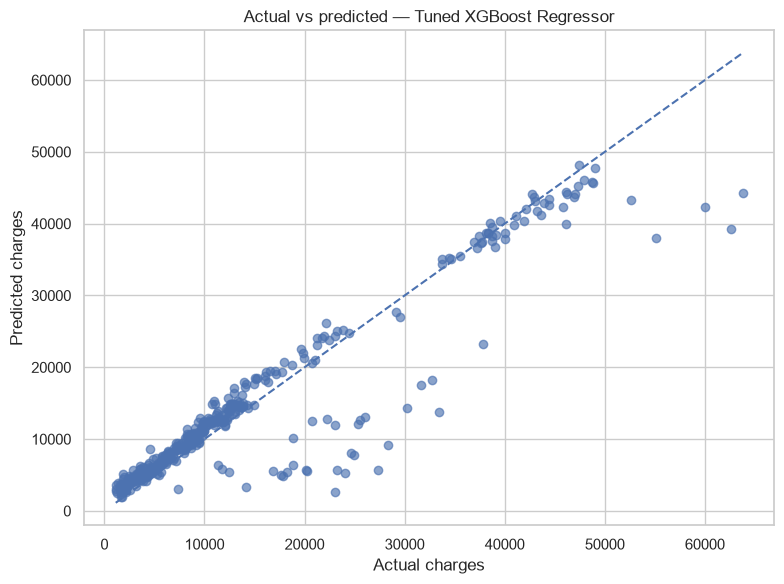

In [17]:
# Top-ranked model by test RMSE
best_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_name]

plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_pred, alpha=0.65)
# Axis range for the reference line
min_v = min(y_test.min(), best_pred.min())
max_v = max(y_test.max(), best_pred.max())
# Dashed y = x line: perfect predictions fall on it
plt.plot([min_v, max_v], [min_v, max_v], linestyle="--")
plt.xlabel("Actual charges")
plt.ylabel("Predicted charges")
plt.title(f"Actual vs predicted — {best_name}")
plt.tight_layout()
plt.show()

### Residual analysis

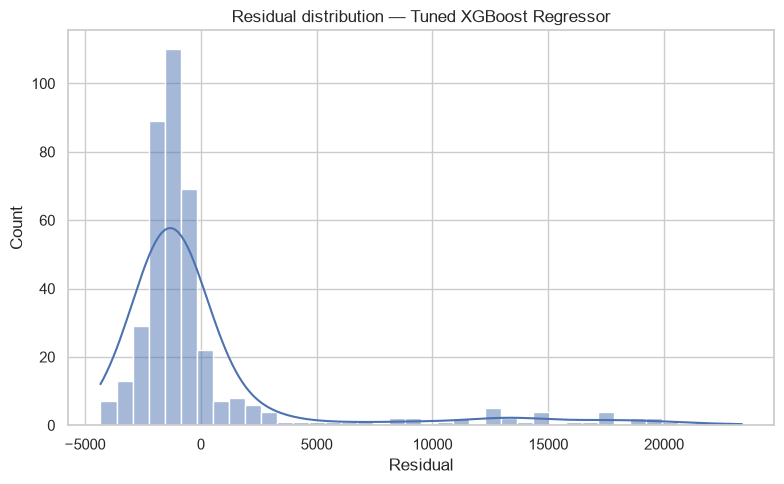

In [18]:
# Residual = actual - predicted
residuals = y_test.to_numpy() - best_pred

plt.figure(figsize=(8, 5))
sns.histplot(residuals, bins=40, kde=True)
plt.title(f"Residual distribution — {best_name}")
plt.xlabel("Residual")
plt.tight_layout()
plt.show()

### Residuals vs predictions

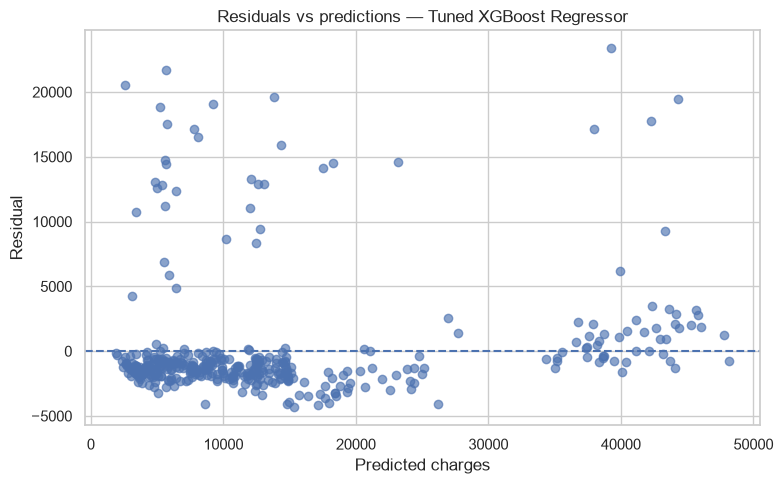

In [19]:
plt.figure(figsize=(8, 5))
plt.scatter(best_pred, residuals, alpha=0.65)
# Zero-residual reference line
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted charges")
plt.ylabel("Residual")
plt.title(f"Residuals vs predictions — {best_name}")
plt.tight_layout()
plt.show()

### Feature importance for XGBoost

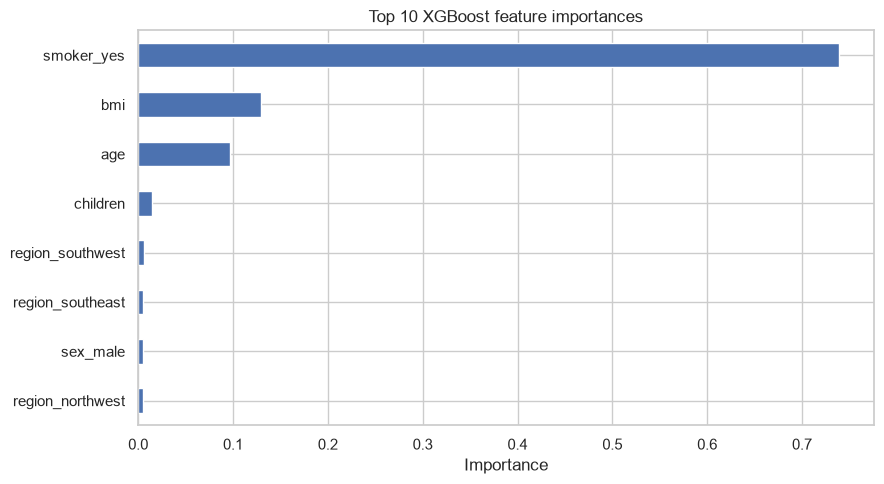


Top XGBoost features:
smoker_yes          0.738963
bmi                 0.128985
age                 0.096816
children            0.014234
region_southwest    0.005957
region_southeast    0.005029
sex_male            0.005027
region_northwest    0.004988
dtype: float32


In [20]:
# Importances of the tuned XGBoost model, sorted descending
importance = pd.Series(
    xgb_model.feature_importances_, index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(9, 5))
# Plot the 10 most important features
importance.head(10).sort_values().plot(kind="barh")
plt.title("Top 10 XGBoost feature importances")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# Print the numeric values
print("\nTop XGBoost features:")
print(importance.head(10))

Conclusions:
1. The target variable is charges.
2. One exact duplicate is removed before model training.
3. High charges are kept because they can be valid insurance cases.
4. Vanilla NumPy and Scikit-learn linear regression produce nearly identical results.
5. XGBoost parameters are selected using 5-fold cross-validation on the training set.
6. A log-target XGBoost model is tested because charges are right-skewed.
7. The previous fixed-weight ensemble is removed because it performed worse than XGBoost.
8. The final model is selected using the lowest test RMSE, with R2 and MAE also considered.